# **1. Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

import warnings
warnings.filterwarnings('ignore')

# **2. Data Loading**

In [2]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data Mining/DataSharing/iris - 3.csv')
data = pd.read_csv('https://raw.githubusercontent.com/data-insight-hub92/data-mining/refs/heads/main/datasets/iris%20-%203.csv')
data.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,7.0,3.2,4.7,1.4,versicolor
1,6.4,3.2,4.5,1.5,versicolor
2,6.9,3.1,4.9,1.5,versicolor
3,5.5,2.3,4.0,1.3,versicolor
4,6.5,2.8,4.6,1.5,versicolor


# **3. Data Inspection**

In [3]:
# Ukuran dataset
print("Ukuran dataset:", data.shape)

# Informasi tipe data dan non-null values
data.info()

Ukuran dataset: (100, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal.Length  100 non-null    float64
 1   Sepal.Width   100 non-null    float64
 2   Petal.Length  100 non-null    float64
 3   Petal.Width   100 non-null    float64
 4   Species       100 non-null    object 
dtypes: float64(4), object(1)
memory usage: 4.0+ KB


In [4]:
# Statistik deskriptif untuk kolom numerik
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Sepal.Length,100.0,6.262,0.662834,4.9,5.800,6.3,6.700,7.9
Sepal.Width,100.0,2.872,0.332751,2.0,2.700,2.9,3.025,3.8
Petal.Length,100.0,4.906,0.825578,3.0,4.375,4.9,5.525,6.9
Petal.Width,100.0,1.676,0.424769,1.0,1.300,1.6,2.000,2.5


In [5]:
# Memeriksa missing values
data.isnull().sum()

,0
Sepal.Length,0
Sepal.Width,0
Petal.Length,0
Petal.Width,0
Species,0


In [6]:
# Memeriksa jumlah baris duplikat
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 1


# **4. Class Distribution Analysis (Before Splitting)**

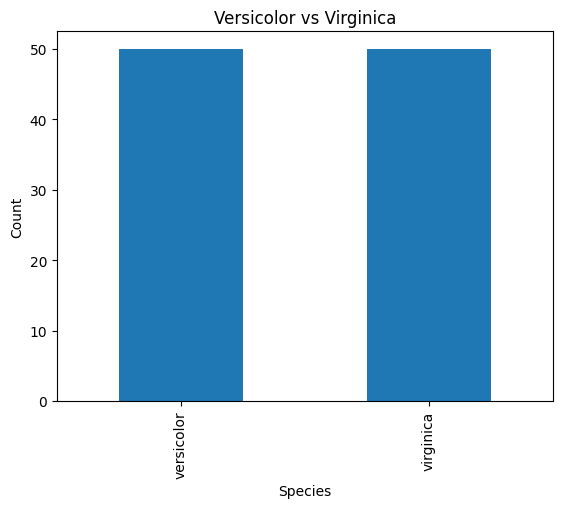

In [7]:
data['Species'].value_counts().plot(kind='bar')
plt.title('Versicolor vs Virginica')
plt.xlabel('Species')
plt.ylabel('Count')
plt.show()

# **5. Define Features and Target**

In [8]:
# Strip any trailing whitespaces from the column names to avoid KeyErrors
data.columns = data.columns.str.strip()

feature_columns = ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width']

X = data[feature_columns]
y = data['Species']

# **6. Train-Test Split**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

**Check Class Distribution After Splitting**

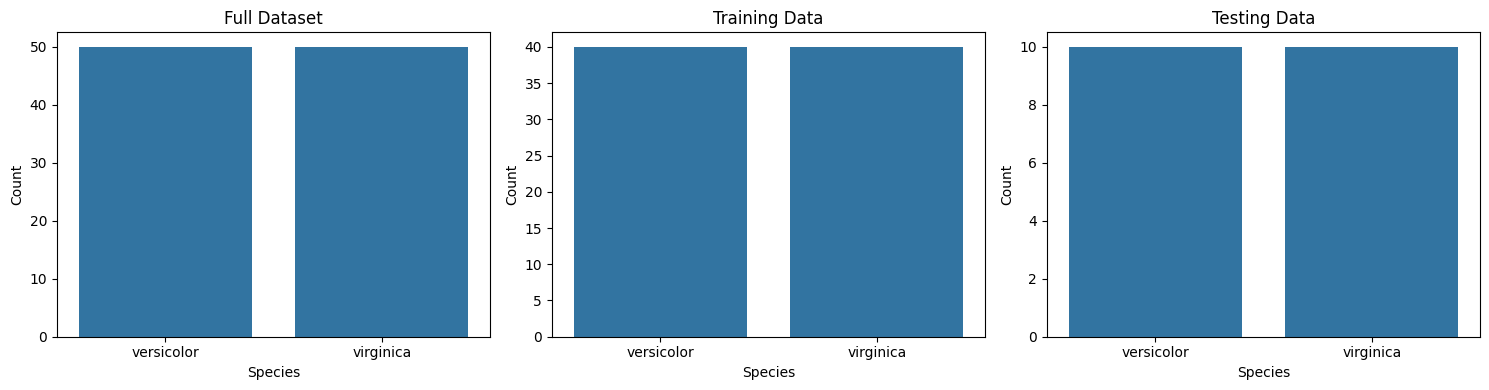

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x=y, ax=axes[0])
axes[0].set_title('Full Dataset')

sns.countplot(x=y_train, ax=axes[1])
axes[1].set_title('Training Data')

sns.countplot(x=y_test, ax=axes[2])
axes[2].set_title('Testing Data')

for ax in axes:
    ax.set_xlabel('Species')
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

# **7. Exploratory Data Analysis (Training Data)**

**7.1 Pairplot: Distribusi dan Hubungan antar-Variabel**

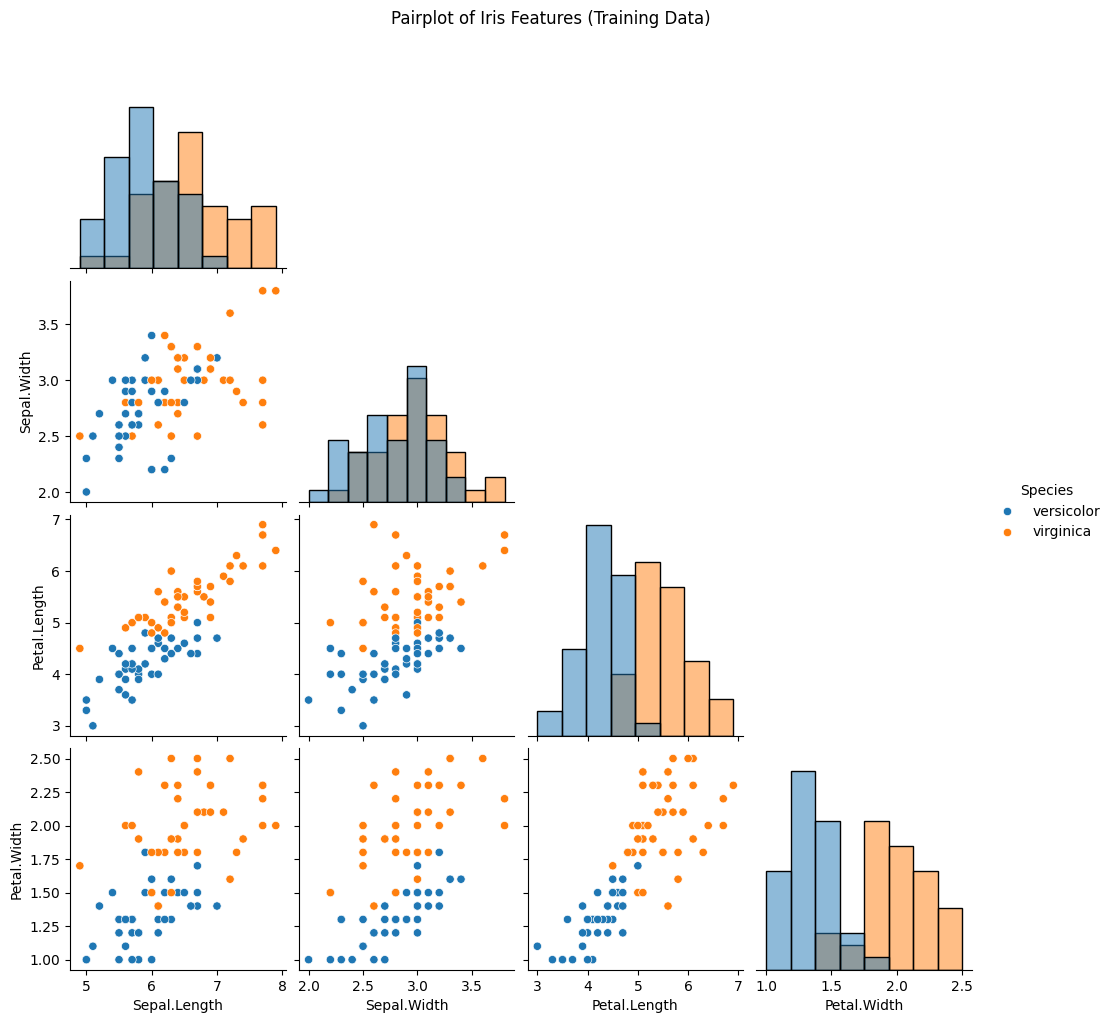

In [11]:
train_data = X_train.copy()
train_data['Species'] = y_train

sns.pairplot(
    train_data,
    vars=feature_columns,
    hue='Species',
    diag_kind='hist',
    corner=True
)

plt.suptitle('Pairplot of Iris Features (Training Data)', y=1.02)
plt.show()

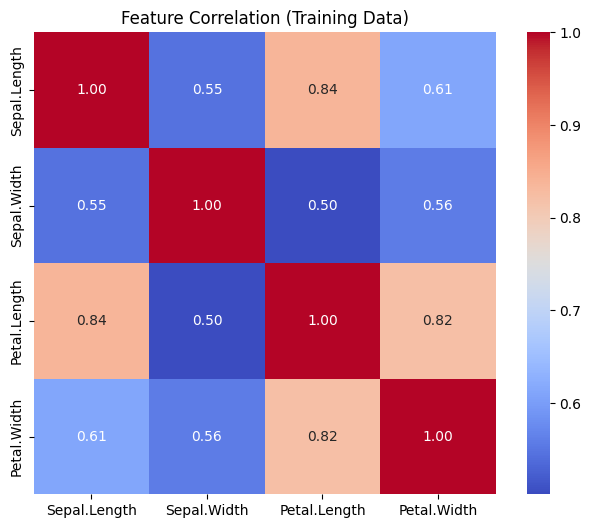

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    X_train.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    square=True
)
plt.title('Feature Correlation (Training Data)')
plt.show()

**7.2 Pemeriksaan Outlier pada Features**

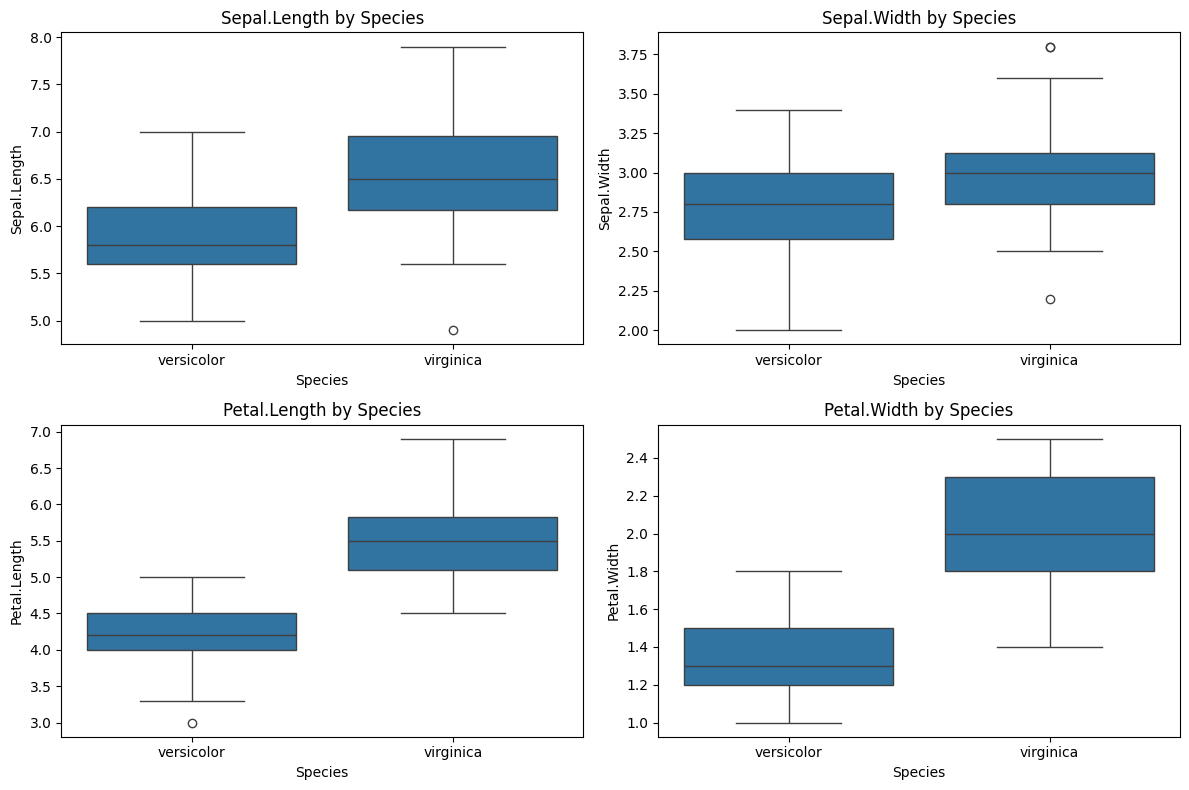

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, feature in zip(axes, feature_columns):
    sns.boxplot(data=train_data, x='Species', y=feature, ax=ax)
    ax.set_title(f'{feature} by Species')

plt.tight_layout()
plt.show()

# **8. Data Preprocessing: Feature Scaling**

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **7. Model Building**

In [15]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean',
    weights='uniform'
)

knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier(metric='euclidean')

# **8. Prediction**

In [16]:
y_pred = knn_model.predict(X_test_scaled)

prediction_results = pd.DataFrame({'Actual': y_test.to_numpy(), 'Predicted': y_pred})
prediction_results.head(10)

,Actual,Predicted
0,versicolor,versicolor
1,virginica,virginica
2,versicolor,versicolor
3,virginica,virginica
4,virginica,virginica
5,virginica,virginica
6,versicolor,versicolor
7,virginica,virginica
8,virginica,virginica
9,virginica,virginica


# **9. Model Evaluation**

In [17]:
# Get predicted probabilities for the positive class ('virginica')
y_pred_proba = knn_model.predict_proba(X_test)[:, 1]

# Calculate metrics using explicit pos_label or probability inputs
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred, pos_label='virginica')
f1_score = metrics.f1_score(y_test, y_pred, pos_label='virginica')
auc = metrics.roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1 Score: {f1_score:.4f}")
print(f"AUC: {auc:.4f}")

Accuracy: 0.9000
Precision: 0.8333
F1 Score: 0.9091
AUC: 0.5000


Classification Report:
              precision    recall  f1-score   support

  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.90        20
   macro avg       0.92      0.90      0.90        20
weighted avg       0.92      0.90      0.90        20



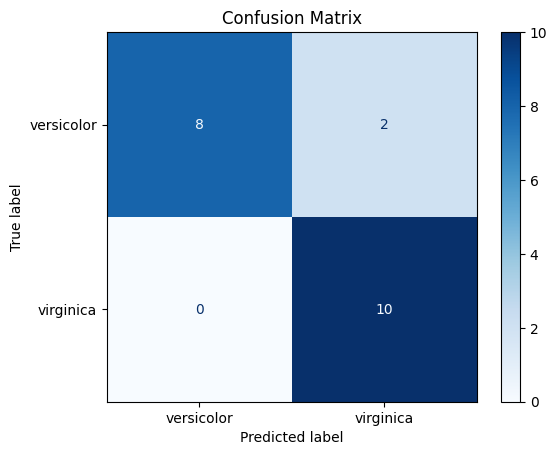

In [18]:
# Display the classification report and confusion matrix instead of regression metrics
print("Classification Report:")
print(metrics.classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = metrics.confusion_matrix(y_test, y_pred)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_model.classes_)
disp.plot(cmap='Blues')
import matplotlib.pyplot as plt
plt.title("Confusion Matrix")
plt.show()